# Compute accuracy plot for sMNIST

I think you could log a bit more cleanly in wandb

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pickle as p
import pandas as pd
import warnings

warnings.simplefilter(action="ignore", category=UserWarning)
warnings.simplefilter(action="ignore", category=RuntimeWarning)

# Use TeX.
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
    }
)

# Configure font sizes.
SMALL_SIZE = 7 + 1
MEDIUM_SIZE = 8 + 1
BIGGER_SIZE = 10 + 1
plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=MEDIUM_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [2]:
with open("./smnist_seq_imzx6zi3.pkl", "rb") as f:
    seq = p.load(f)

In [3]:
with open("./smnist_977si1an.pkl", "rb") as f:
    parr = p.load(f)

In [4]:
parr

,_timestamp,val_loss,_runtime,train_time,trainer/global_step,val_accuracy,test_loss,_step,test_accuracy,run_id,...,trainer_cfg,model_cfg.clip,Comment,model_cfg.method,model_cfg.parallel,data_cfg,model_cfg.num_iters,optimizer_cfg,logger_cfg,seed
0,1.735624e+09,NaN,198.159096,195.055585,0,NaN,NaN,0,NaN,ws15rhrp,...,NaN,False,# yaml file for using hydra for sequential mni...,gru,True,NaN,10,NaN,NaN,2
1,1.735624e+09,1.760498,204.793956,NaN,0,0.339833,NaN,1,NaN,ws15rhrp,...,NaN,False,# yaml file for using hydra for sequential mni...,gru,True,NaN,10,NaN,NaN,2
2,1.735624e+09,NaN,399.475700,194.676997,1,NaN,NaN,2,NaN,ws15rhrp,...,NaN,False,# yaml file for using hydra for sequential mni...,gru,True,NaN,10,NaN,NaN,2
3,1.735624e+09,1.412253,406.090436,NaN,1,0.485667,NaN,3,NaN,ws15rhrp,...,NaN,False,# yaml file for using hydra for sequential mni...,gru,True,NaN,10,NaN,NaN,2
4,1.735624e+09,NaN,600.802524,194.707307,2,NaN,NaN,4,NaN,ws15rhrp,...,NaN,False,# yaml file for using hydra for sequential mni...,gru,True,NaN,10,NaN,NaN,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7376,1.735595e+09,NaN,581.674228,12.368061,42,NaN,NaN,84,NaN,3jpvdzui,...,NaN,True,# yaml file for using hydra for sequential mni...,minrnn,True,NaN,1,NaN,NaN,0
7377,1.735595e+09,1.130273,582.705162,NaN,42,0.608000,NaN,85,NaN,3jpvdzui,...,NaN,True,# yaml file for using hydra for sequential mni...,minrnn,True,NaN,1,NaN,NaN,0
7378,1.735595e+09,NaN,595.255993,12.549645,43,NaN,NaN,86,NaN,3jpvdzui,...,NaN,True,# yaml file for using hydra for sequential mni...,minrnn,True,NaN,1,NaN,NaN,0
7379,1.735595e+09,1.150541,596.282099,NaN,43,0.594333,NaN,87,NaN,3jpvdzui,...,NaN,True,# yaml file for using hydra for sequential mni...,minrnn,True,NaN,1,NaN,NaN,0


In [31]:
num_steps_df = parr[parr["model_cfg.method"] == "gru"][["model_cfg.num_iters" , "trainer/global_step", "seed"]].groupby(["model_cfg.num_iters", "seed"]).max().groupby("model_cfg.num_iters").mean()

In [25]:
seq[["trainer/global_step", "seed"]].groupby(
    ["seed"]
).max().mean().item()

trainer/global_step    34.333333
dtype: float64

In [39]:
134.581443 * 34.33

4620.18093819

In [16]:
parr[~parr["model_cfg.clip"]][parr["model_cfg.method"] == "gru"][
    ~parr["_runtime"].isna()
][["model_cfg.num_iters", "_runtime"]]

,model_cfg.num_iters,_runtime
0,10,198.159096
1,10,204.793956
2,10,399.475700
3,10,406.090436
4,10,600.802524
...,...,...
1805,1,1053.705540
1806,1,1054.775736
1807,1,1072.066367
1808,1,1073.134887


In [32]:
time_per_step_df = parr[~parr["model_cfg.clip"]][parr["model_cfg.method"] == "gru"][
    ~parr["train_time"].isna()
][[ "model_cfg.num_iters", "train_time"]].groupby(["model_cfg.num_iters"]).mean()

In [36]:
both_df = time_per_step_df.join(num_steps_df)

In [45]:
both_df["total_time"] = both_df["train_time"] * both_df["trainer/global_step"] / 60
both_df

,train_time,trainer/global_step,total_time
model_cfg.num_iters,,,
1,17.338730,58.666667,16.953425
2,36.967510,89.333333,55.040515
3,56.711321,65.000000,61.437264
4,76.445398,41.333333,52.662385
5,96.303198,32.666667,52.431741
10,195.066618,32.333333,105.119233


In [46]:
134.581443 * 34.33 / 60

77.00301563650001

In [49]:
both_df.index

Index([1, 2, 3, 4, 5, 10], dtype='int64', name='model_cfg.num_iters')

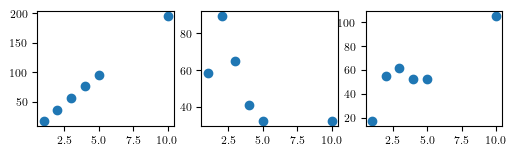

In [52]:
fig, axs = plt.subplots(1, 3, figsize=(6, 1.5))

axs[0].scatter(both_df.index, both_df["train_time"])
axs[0].set_xlabel("Train time (s)")

axs[1].scatter(both_df.index, both_df["trainer/global_step"])

axs[2].scatter(both_df.index, both_df["total_time"])

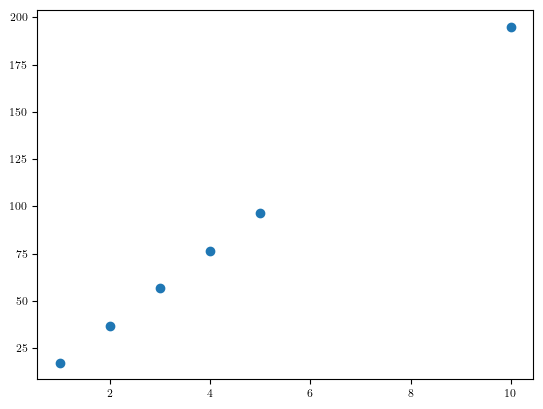

In [50]:
plt.scatter(both_df.index, both_df['train_time'])

In [10]:
seq[~seq["train_time"].isna()][["train_time"]].mean()

train_time    134.581443
dtype: float64

In [5]:
parr[~parr["model_cfg.clip"]][parr["model_cfg.method"] == "gru"][
    ~parr["test_accuracy"].isna()
][["seed", "model_cfg.num_iters", "test_accuracy", "train_time"]].groupby(
    ["model_cfg.num_iters"]
).mean()

,seed,test_accuracy,train_time
model_cfg.num_iters,,,
1,1.0,0.639700,NaN
2,1.0,0.892167,NaN
3,1.0,0.971933,NaN
4,1.0,0.971833,NaN
5,1.0,0.964800,NaN
10,1.0,0.984300,NaN


In [54]:
parr_series = parr[~parr["model_cfg.clip"]][parr["model_cfg.method"]=='gru'][~parr["test_accuracy"].isna()][
    ["seed", "model_cfg.num_iters", "test_accuracy"]
].groupby(["model_cfg.num_iters"]).mean().unstack()['test_accuracy']
parr_series_std = (
    parr[~parr["model_cfg.clip"]][parr["model_cfg.method"] == "gru"][
        ~parr["test_accuracy"].isna()
    ][["seed", "model_cfg.num_iters", "test_accuracy"]]
    .groupby(["model_cfg.num_iters"])
    .std()
    .unstack()["test_accuracy"]
)
num_iters = parr_series.index.tolist()
test_accuracy = [100 * t for t in parr_series.values.tolist()]
test_accuracy_std = parr_series_std.values.tolist()

In [56]:
seq_test_acc = (
    seq[~seq["test_accuracy"].isna()][["test_accuracy"]].mean().item()
)  
seq_test_std = seq[~seq["test_accuracy"].isna()][["test_accuracy"]].std().item()
print(f"the accuracy of sequential is {round(100 * seq_test_acc, 2)}")
print(f"the standard deviation of sequential over 3 seeds is {round(100 * seq_test_std, 2)}")

the accuracy of sequential is 98.51
the standard deviation of sequential over 3 seeds is 0.24


In [72]:
test_accuracy

[63.96999955177307,
 89.21666344006857,
 97.19333052635193,
 97.18333085378012,
 96.47999604543051,
 98.42999974886575]

In [73]:
test_accuracy_std

[0.0074806384379223914,
 0.026958533597578903,
 0.003914488130338419,
 0.01137996799484461,
 0.023586439294625134,
 0.0001731994095344338]

<>:9: SyntaxWarning: invalid escape sequence '\%'
<>:9: SyntaxWarning: invalid escape sequence '\%'
/var/folders/tf/ybkfqmld4yb8_yn2xr11sl8m0000gn/T/ipykernel_39889/3396441856.py:9: SyntaxWarning: invalid escape sequence '\%'
  axs.set_ylabel("Test accuracy (\%)")


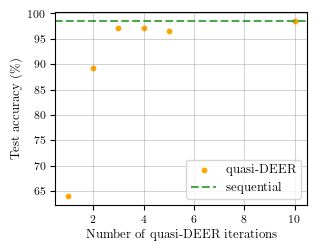

In [90]:
# Create figure and axes
fig, axs = plt.subplots(figsize=(3.25, 2.5))

# Scatter plot
axs.scatter(num_iters, test_accuracy, s=10, color="orange", label="quasi-DEER")

# Labels
axs.set_xlabel("Number of quasi-DEER iterations")
axs.set_ylabel("Test accuracy (\%)")

# Horizontal line
axs.set_xlim(0.5, 10.5)  # Adjust as needed to add some padding
axs.hlines(
    100 * seq_test_acc, xmin=0.5, xmax=10.5, linestyle="--", alpha=0.7, color='green', label="sequential"
)

# Add grid
axs.grid(color="gray", linewidth=0.5, alpha=0.5)
axs.legend(loc="lower right")  # Adjust location as needed
plt.savefig("smnist_compute_accuracy.pdf", bbox_inches="tight")

<>:12: SyntaxWarning: invalid escape sequence '\%'
<>:28: SyntaxWarning: invalid escape sequence '\#'
<>:40: SyntaxWarning: invalid escape sequence '\#'
<>:51: SyntaxWarning: invalid escape sequence '\#'
<>:12: SyntaxWarning: invalid escape sequence '\%'
<>:28: SyntaxWarning: invalid escape sequence '\#'
<>:40: SyntaxWarning: invalid escape sequence '\#'
<>:51: SyntaxWarning: invalid escape sequence '\#'
/var/folders/tf/ybkfqmld4yb8_yn2xr11sl8m0000gn/T/ipykernel_4293/1542874104.py:12: SyntaxWarning: invalid escape sequence '\%'
  axs[0,0].set_ylabel("Test accuracy (\%)")
/var/folders/tf/ybkfqmld4yb8_yn2xr11sl8m0000gn/T/ipykernel_4293/1542874104.py:28: SyntaxWarning: invalid escape sequence '\#'
  axs[1, 0].set_xlabel("\# quasi-DEER iters")
/var/folders/tf/ybkfqmld4yb8_yn2xr11sl8m0000gn/T/ipykernel_4293/1542874104.py:40: SyntaxWarning: invalid escape sequence '\#'
  axs[0,1].set_ylabel("\# Train epochs")
/var/folders/tf/ybkfqmld4yb8_yn2xr11sl8m0000gn/T/ipykernel_4293/1542874104.py:51: S

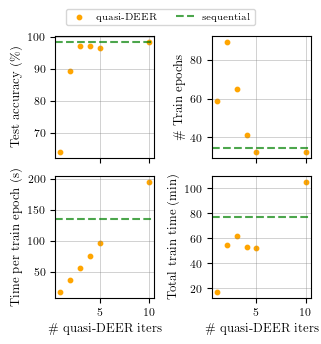

In [84]:
seq_train_time = seq[~seq["train_time"].isna()][["train_time"]].mean()
seq_train_epochs = seq[["trainer/global_step", "seed"]].groupby(
    ["seed"]
).max().mean().item()

fig, axs = plt.subplots(2, 2, figsize=(3.25,3.25), sharex=True)

# Scatter plot
axs[0,0].scatter(num_iters, test_accuracy, s=10, color="orange", label="quasi-DEER")

# Labels
axs[0,0].set_ylabel("Test accuracy (\%)")

# Horizontal line
axs[0,0].set_xlim(0.5, 10.5)  # Adjust as needed to add some padding
axs[0,0].hlines(
    100 * seq_test_acc,
    xmin=0.5,
    xmax=10.5,
    linestyle="--",
    alpha=0.7,
    color="green",
    label="sequential",
)


axs[1, 0].scatter(both_df.index, both_df["train_time"], s=10, color="orange")
axs[1, 0].set_xlabel("\# quasi-DEER iters")
axs[1, 0].set_ylabel("Time per train epoch (s)")
axs[1, 0].hlines(
    seq_train_time,
    xmin=0.5,
    xmax=10.5,
    linestyle="--",
    alpha=0.7,
    color="green",
)

axs[0, 1].scatter(both_df.index, both_df["trainer/global_step"], s=10, color="orange")
axs[0,1].set_ylabel("\# Train epochs")
axs[0, 1].hlines(
    seq[["trainer/global_step", "seed"]].groupby(["seed"]).max().mean().item(),
    xmin=0.5,
    xmax=10.5,
    linestyle="--",
    alpha=0.7,
    color="green",
)

axs[1, 1].scatter(both_df.index, both_df["total_time"], s=10, color="orange")
axs[1, 1].set_xlabel("\# quasi-DEER iters")
axs[1,1].set_ylabel("Total train time (min)")
axs[1, 1].hlines(
    seq_train_time * seq_train_epochs / 60,
    xmin=0.5,
    xmax=10.5,
    linestyle="--",
    alpha=0.7,
    color="green",
)

for ax in axs.flat:
    ax.grid(color="gray", linewidth=0.5, alpha=0.5)


fig.legend(
    loc="upper center",  # Position the legend at the top center
    bbox_to_anchor=(
        0.5,
        1.05,
    ),  # Adjust the position (x=0.5 centers it, y=1.05 places it above)
    ncol=2,  # Number of columns in the legend
    fontsize="small",  # Optional: Adjust font size
)
plt.tight_layout()
plt.savefig("smnist_with_timing.pdf", bbox_inches="tight")